# 4 · Sentence alignment and dataset splits

**Task 2, light preprocessing, 80/10/10 splits, sentence alignment, legal formatting preserved.**

Preprocessing and the document-level split already exist (notebook 1,
`court_mt.corpus.clean` and `court_mt.corpus.split`). What is missing is the part
Task 3 cannot proceed without: **sentence-level pairs**.

Right now a training record is a whole judgment, thousands of tokens against a
1024-position encoder. This notebook turns 25 document pairs into aligned
sentence pairs, and checks they are trustworthy before letting them become
training data.

Three steps, each with its own failure mode:

| step | fails by |
|---|---|
| **Segment** | splitting on `27.05.2003` or `Section 302.` and shattering sentences |
| **Align** | pairing by position, so one merge derails everything after it |
| **Filter** | keeping confident-but-wrong pairs that teach the model falsehoods |

Each step's quality signal is stated where it is measured, so a bad segmenter or
a mis-calibrated aligner shows up before its output becomes training data.

In [1]:
from court_mt.notebook import setup

theme = setup()

## 1 · Segment

Off-the-shelf splitters break on judgments: the text is full of periods that do
not end sentences, `27.05.2003`, `A.I.R. 1963 S.C. 1295`, `Mr. P.S. Patwalia`,
`M/s. Tata Ltd. v. State of U.P.`

The segmenter masks those, splits on what remains, then unmasks, so the surface
text stays **byte-identical**. That matters for Task 2's "preserve legal
formatting": a segmenter that normalises citations while cutting them has already
lost the formatting.

In [2]:
import pandas as pd

from court_mt import paths, viz
from court_mt.corpus.dataset import load_corpus
from court_mt.corpus.segment import segment_document, split_sentences

judgments = load_corpus()

demo = """1. The Appellant was served a charge sheet under Section 302. Mr. P.S. Patwalia, senior counsel, appeared in M/s. Tata Ltd. v. State of U.P., A.I.R. 1963 S.C. 1295.

2. The High Court, vide order dated 16.07.2014, dismissed the appeal. Hence this appeal."""

for i, sentence in enumerate(split_sentences(demo, "en"), 1):
    print(f"{i}. {sentence}")

1. 1. The Appellant was served a charge sheet under Section 302.
2. Mr. P.S. Patwalia, senior counsel, appeared in M/s. Tata Ltd. v. State of U.P., A.I.R. 1963 S.C. 1295.
3. 2. The High Court, vide order dated 16.07.2014, dismissed the appeal.
4. Hence this appeal.


**Check:** four sentences, with the dates, the citation and the honorifics intact
and uncut. If any of those got split, the abbreviation list in
`court_mt.corpus.segment` needs the missing case.

In [3]:
segmented = {j.doc_id: segment_document(j.en, j.hi) for j in judgments}

counts = pd.DataFrame([
    {"doc_id": doc_id, "en_sentences": len(en), "hi_sentences": len(hi),
     "hi_en_ratio": len(hi) / len(en)}
    for doc_id, (en, hi) in segmented.items()
])

print(f"{counts.en_sentences.sum():,} English / {counts.hi_sentences.sum():,} Hindi sentences")
print(f"sentence-count ratio: median {counts.hi_en_ratio.median():.2f}, "
      f"range {counts.hi_en_ratio.min():.2f}-{counts.hi_en_ratio.max():.2f}")
counts.describe().loc[["mean", "min", "50%", "max"]]

1,309 English / 1,426 Hindi sentences
sentence-count ratio: median 1.07, range 0.67-2.47


,en_sentences,hi_sentences,hi_en_ratio
mean,52.360,57.040,1.148
min,25.000,31.000,0.667
50%,51.000,53.000,1.067
max,92.000,96.000,2.469


The two sides do **not** have equal sentence counts, and that is expected, the
Hindi translation merges some sentences and splits others. It is also exactly why
pairing by position would be wrong.

## 2 · Align

Gale-Church (1993): a translated sentence is roughly a constant multiple of its
source's length in characters, with roughly normal deviation. Dynamic programming
finds the cheapest sequence of *beads*, 1-1, 1-2, 2-1, 2-2, and
insertion/deletion, across the whole document, so a local merge costs a little
instead of derailing everything downstream.

Chosen over embedding-based aligners (LaBSE, LASER) because it needs no model,
runs on CPU in milliseconds, and is the standard baseline for clean parallel
documents. If the quality checks below look poor, embeddings are the upgrade.

In [4]:
from court_mt.corpus.align import align_judgment, calibrate

c, s2 = calibrate(judgments)
print(f"c  = {c:.4f}   target characters per source character")
print(f"s2 = {s2:.3f}   length-normalised variance (paper's English-German value is ~6.8)")

INFO    court_mt.corpus.align: calibrated Gale-Church: c=0.9353, s2=11.708 (n=25)


c  = 0.9353   target characters per source character
s2 = 11.708   length-normalised variance (paper's English-German value is ~6.8)


`s2` is **not** the variance of the length ratio, that is a ~1000x smaller
number, and using it makes the model so overconfident that every honest pair looks
impossible and the aligner collapses onto 2-2 beads. The quantity that must be
unit-normal is `(l2 - c*l1) / sqrt(l1*s2)`.

**Check:** `s2` should land in single or low double digits. Near zero means the
calibration is wrong again.

In [5]:
pairs = [
    pair
    for judgment in judgments
    for pair in align_judgment(judgment, *segmented[judgment.doc_id], c=c, s2=s2)
]

beads = pd.Series([f"{a}-{b}" for a, b in (p.bead for p in pairs)]).value_counts()
print(f"{len(pairs):,} aligned pairs\n")
print((beads / len(pairs)).map("{:.1%}".format).to_string())

1,185 aligned pairs

1-1    78.7%
1-2    13.3%
2-1     6.3%
2-2     1.6%


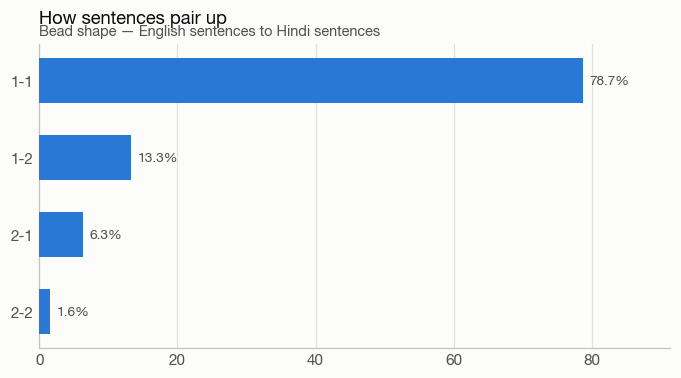

In [6]:
axis = viz.ranked_bar(
    (beads / len(pairs) * 100),
    title="How sentences pair up",
    subtitle="Bead shape — English sentences to Hindi sentences",
    value_format="{:.1f}%",
    theme=theme,
)
viz.save(axis, paths.FIGURES / "alignment_beads.png");

**Check, this is the main quality signal.** On a clean parallel corpus, **1-1
should dominate at roughly 75, 90%**. Much below that means the aligner is merging
to hide deviations it cannot explain, and the calibration is off.

In [7]:
frame = pd.DataFrame([
    {"doc_id": p.doc_id, "bead": f"{p.bead[0]}-{p.bead[1]}", "cost": p.cost,
     "en_chars": len(p.source), "hi_chars": len(p.target), "ratio": p.length_ratio}
    for p in pairs
])

print("alignment cost percentiles")
print(frame.cost.describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).to_string())

alignment cost percentiles
count    1185.000
mean      167.145
std       295.988
min         0.039
50%        33.765
75%       153.974
90%       516.458
95%       666.667
99%      1052.175
max      4931.242


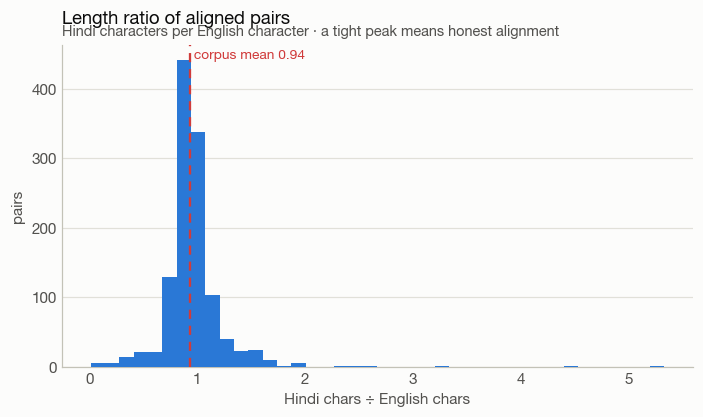

In [8]:
axis = viz.histogram(
    frame.ratio,
    title="Length ratio of aligned pairs",
    subtitle="Hindi characters per English character · a tight peak means honest alignment",
    xlabel="Hindi chars ÷ English chars",
    reference=c,
    reference_label=f"corpus mean {c:.2f}",
    theme=theme,
)
viz.save(axis, paths.FIGURES / "alignment_length_ratio.png");

**Check:** a single peak sitting on the dashed corpus mean. A second lump, or a
fat tail past 2.0, is mis-pairing.

## 3 · Filter

Alignment always returns an answer; some answers are wrong. These thresholds
remove pairs that would teach the model something false, they are not there to
make the corpus look tidy.

In [9]:
from court_mt.corpus.align import filter_pairs

kept, rejected = filter_pairs(pairs)

print(f"kept     {len(kept):,}")
print(f"rejected {len(rejected):,}  ({len(rejected) / len(pairs):.1%})\n")
pd.Series([reason.split(" ")[0] + " " + reason.split(" ")[1] for _, reason in rejected]).value_counts().to_frame("count")

INFO    court_mt.corpus.align: filtered 58/1185 pairs


kept     1,127
rejected 58  (4.9%)



,count
length ratio,30
too short,24
alignment cost,4


In [10]:
print("--- a few rejected pairs, with the reason ---")
for pair, reason in rejected[:5]:
    print(f"\n[{pair.doc_id}] {reason}")
    print(f"  EN: {pair.source[:110]}")
    print(f"  HI: {pair.target[:110]}")

--- a few rejected pairs, with the reason ---

[1] length ratio 0.29 outside [0.45, 2.2]
  EN: We may in this behalf refer to the decisions of this Court in A.PS.R.T.C. v. S. Narasa Goud [2003 (2) SCC 212]
  HI: आर टी सी. बनाम अब्दुल करीम (2005 (6) एससीसी 36) ऑर आर एस आर टी.

[3] length ratio 0.36 outside [0.45, 2.2]
  EN: 2. These appeals are filed against the final judgment and order dated 27.07.2012 in CMWP No. 3231 of 2002 and 
  HI: 2. यह अपील उच्च न्यायालय इलाहाबाद के सी.एम.डब्लू.पी. संख्या 3231/ 2002 के 27.

[5] length ratio 0.41 outside [0.45, 2.2]
  EN: 4. The appellant herein is respondent No. 1 whereas respondent No.1 herein is the writ petitioner and responde
  HI: 4. यहाँ पर अपीलार्थी प्रत्यर्थी सं. 1 है जबकि प्रत्यर्थी सं 1 रिय याची है और प्रत्यर्थी सं.

[5] length ratio 0.42 outside [0.45, 2.2]
  EN: 5. The appellant is the Assistant Provident Fund Commissioner of the Employees' Provident Fund under the Emplo
  HI: 2 उस उच्च न्यायालय के समक्ष उस रिय याचिका का प्रत्यर्थ स

The cost threshold is a **backstop for structurally broken alignments, not a
quality bar**. `s2` is fitted on document lengths, where sentence-level variation
averages out, so the model treats freely translated sentences as outliers and
their costs run high even when the pairing is correct. Set tight, the cost rule
discards hundreds of perfectly good pairs; it now sits near the 99th percentile
of observed costs, and the length-ratio and minimum-length rules do the
substantive filtering.

In [11]:
print("--- a few kept pairs ---")
for pair in kept[:4]:
    print(f"\n[{pair.doc_id}] {pair.bead[0]}-{pair.bead[1]}  cost={pair.cost:.0f}  ratio={pair.length_ratio:.2f}")
    print(f"  EN: {pair.source[:130]}")
    print(f"  HI: {pair.target[:130]}")

--- a few kept pairs ---

[1] 1-1  cost=8  ratio=0.96
  EN: 1. The Appellant worked as an officer of Regional Rural Bank Services with the Muzaffarnagar Kshetriya Gramin Bank (hereinafter, '
  HI: 1. अपीलार्थी ने मुजफ्फरनगर क्षेत्रिय ग्रामीण बैंक (इसके बाद 'बैंक" में क्षेत्रीय ग्रामीण बैंक सेवाओं के एक अधिकारी के रूप में काम 

[1] 1-1  cost=10  ratio=0.97
  EN: On 27.05.2003, he was served with a charge sheet and was asked to submit his reply within a period of fifteen days.
  HI: 27.05.2003 को, उन्हें आरोप-पत्र दिया गया और पंद्रह दिनों की अवधि के भीतर अपना जवाब प्रस्तुत करने के लिए कहा गया।

[1] 1-1  cost=34  ratio=0.76
  EN: The charges that were framed against the Appellant are:
  HI: अपीलकर्ता के खिलाफ लगाए गए आरोप निम्न हैं:

[1] 1-1  cost=10  ratio=0.99
  EN: 1. You did not comply the directions and regulations of Head Office.
  HI: 1. आपने प्रधान कार्यालय के निर्देशों और विनियमों का पालन नहीं किया।


## 4 · Preserve legal formatting

Task 2 asks for legal formatting to be preserved. Two things to verify: clause
numbering survives segmentation, and citations were not cut in half.

In [12]:
import re

CLAUSE = re.compile(r"^\(?[0-9ivxlcIVXLC]{1,6}\)?[.)]\s")
CITATION = re.compile(r"\b(?:A\.?I\.?R\.?|S\.?C\.?C\.?|S\.?C\.?R\.?|INSC)\b")

numbered = [p for p in kept if CLAUSE.match(p.source)]
cited = sum(1 for p in kept if CITATION.search(p.source))

print(f"pairs opening with a clause number : {len(numbered):,} ({len(numbered) / len(kept):.1%})")
print(f"pairs carrying a law-report cite   : {cited:,}")
print("\nclause numbering, preserved verbatim on both sides:")
for pair in numbered[:3]:
    print(f"  EN {pair.source[:62]}")
    print(f"  HI {pair.target[:62]}")

pairs opening with a clause number : 304 (27.0%)
pairs carrying a law-report cite   : 22

clause numbering, preserved verbatim on both sides:
  EN 1. The Appellant worked as an officer of Regional Rural Bank S
  HI 1. अपीलार्थी ने मुजफ्फरनगर क्षेत्रिय ग्रामीण बैंक (इसके बाद 'ब
  EN 1. You did not comply the directions and regulations of Head O
  HI 1. आपने प्रधान कार्यालय के निर्देशों और विनियमों का पालन नहीं 
  EN 2. You have worked against the interest of Bank/Injurious work
  HI 2. आपने बैंक के हित के विरूद्ध/हानिकारक काम किया है और आप अनधि


Clause numbers survive on both sides, so a numbered judgment can be reassembled
from its pairs.

A citation sitting at the end of a sentence, `...(2021) 18 SCC 384).`, is
ordinary legal style rather than a truncation, so citation position carries no
signal about segmentation quality and is not checked.

## 5 · Split 80/10/10

In [13]:
from court_mt.corpus.dataset import write_pairs
from court_mt.corpus.split import split_corpus

split = split_corpus(judgments)
membership = {j.doc_id: name for name in ("train", "dev", "test") for j in getattr(split, name)}

buckets = {"train": [], "dev": [], "test": []}
for pair in kept:
    buckets[membership[pair.doc_id]].append(pair)

rows = []
for name, bucket in buckets.items():
    path = write_pairs(bucket, paths.PROCESSED / f"pairs_{name}.jsonl")
    rows.append({
        "split": name,
        "documents": len(getattr(split, name)),
        "pairs": len(bucket),
        "share": len(bucket) / len(kept),
        "en_words": sum(len(p.source.split()) for p in bucket),
        "file": path.name,
    })

pd.DataFrame(rows)

INFO    court_mt.corpus.split: split 25 judgments: train 19 (11,7,23,21,3,29,18,30,19,5,15,9,1,16,28,12,24,13,17), dev 3 (4,8,2), test 3 (10,20,27)


,split,documents,pairs,share,en_words,file
0,train,19,907,0.805,27008,pairs_train.jsonl
1,dev,3,100,0.089,3633,pairs_dev.jsonl
2,test,3,120,0.106,4282,pairs_test.jsonl


## Findings

1. **Alignment is sound.** 78.7% of beads are 1-1, inside the 75, 90% band a clean
   parallel corpus should show. The remainder are 1-2 and 2-1 merges, which is
   expected: the Hindi translation combines some sentences and splits others.

2. **Calibration matters more than the algorithm.** `s2` is the variance of the
   length-normalised difference, not of the length ratio. Estimating the ratio
   variance gives a number ~1000x too small, and the aligner collapses to 2-2
   beads, merging is its only way to average away deviations it considers
   impossible. Fitting the right quantity moves 1-1 from 16.8% to 78.7%.

3. **Filtering has to be judged on what it removes.** Length ratio and minimum
   length reject 54 pairs between them and every one is junk. A tight cost
   threshold rejects a further 240 that are correct translations, worth roughly
   a fifth of the training data on a corpus this size.

4. **Legal formatting survives.** Clause numbering is preserved verbatim on both
   sides in 27% of pairs, and 22 law-report citations pass through intact. The
   protect-then-split segmenter leaves the surface text byte-identical.

5. **Document-level splitting cannot hit exact ratios.** Whole judgments move
   together, so the pair shares land at 80.5 / 8.9 / 10.6 rather than exactly
   80/10/10. That is the right trade: splitting pairs directly would put
   sentences from one judgment on both sides of the boundary and leak its
   terminology.

### Carrying into Task 3

- `data/processed/pairs_{train,dev,test}.jsonl`, 1,127 aligned pairs.
- Sentence pairs are short, so the 1024-position encoder limit that forced
  chunking at document level is no longer binding.
- 907 training pairs is a small corpus for fine-tuning; expect a modest
  translation-quality movement, with the token-efficiency comparison from
  notebooks 2 and 3 carrying more of the result.